# URM fragility curves: parameters and plots

This notebook gives the seismic fragility curves for **unreinforced masonry (URM) buildings** from Monteferrante et al. (2025), *Earthquake Engineering & Structural Dynamics* 54:2927-2946, which were derived from damage data from the 2012 Emilia earthquakes.

## What this notebook does

For a building of your choice, defined by its **construction year** and **number of storeys**, and an **intensity measure (IM)** of your choice, the notebook:

1. returns the **fragility parameters** $\mu_i$ and $\sigma$,
2. calculates the **probability of damage** for a given IM value, and
3. **plots the fragility curves**.

It does not calculate the ground-motion intensity itself. The IM value is an input, for example from a seismic hazard analysis.

## The fragility curves

For each damage state $D_i$ (D1 to D5), the probability of reaching or exceeding it, given an IM value, is

$$P(D \geq D_i \mid IM) = \Phi\left(\frac{\log_{10}(IM) - \mu_i}{\sigma}\right)$$

where $\Phi$ is the standard normal cumulative distribution function. In this equation:

* **IM** is the intensity measure value, in **g**
* $\mu_i$ is the fragility parameter for damage state $D_i$. There is one value for each of the five damage states.
* $\sigma$ is a single value, the same for all damage states
* $\mu_i$ and $\sigma$ are in **log base 10**

D1 is slight damage and D5 is partial or total collapse (EMS-98 based scale, Table 1 of the paper).

## Intensity measures

| `im` | Meaning |
|---|---|
| `PGA` | Peak ground acceleration |
| `Sa_0.3`, `Sa_0.75`, `Sa_1.5` | Spectral acceleration at **one** period (0.3, 0.75 or 1.5 s) |
| `Sa_avg` | **Average** spectral acceleration: the geometric mean of Sa(T) over periods from 0.1 to 0.5 s |

All values are in g. `Sa_avg` is a different quantity from the single-period Sa values, so use each with its own `im` name.

## Where the parameters come from

* **PGA:** the paper gives $\mu_i$ and $\sigma$ directly (Table 13). They are stored in `data/` and read from there.
* **Sa measures:** the paper gives a regression model (Table 11) instead of the parameters. The code in `urm_fragility.py` evaluates this regression for the chosen building and converts the result into $\mu_i$ and $\sigma$.



In [9]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import urm_fragility as uf


## 1. Choose a building

* `year`: construction year
* `Ns`: number of storeys (5 or more count as 5)
* `ims`: the intensity measures to look at

In [2]:
year = 1940    # construction year
Ns = 3         # number of storeys (5 or more count as 5)

ims = ["PGA", "Sa_0.3", "Sa_0.75", "Sa_1.5", "Sa_avg"]

## 2. Fragility parameters

`get_fragility_parameters(year, Ns, im)` returns:

* `mu`: an array of 5 values, one for each damage state D1 to D5
* `sigma`: a single value

In [3]:
mu, sigma = uf.get_fragility_parameters(year, Ns, "PGA")

print("mu    =", mu.round(4))
print("sigma =", round(sigma, 4))

mu    = [-0.6819 -0.465  -0.3439 -0.2255  0.1244]
sigma = 0.4126


The same for every intensity measure, in one table:

In [4]:
rows = {}
for im in ims:
    mu, sigma = uf.get_fragility_parameters(year, Ns, im)
    rows[im] = [*mu, sigma]

params = pd.DataFrame(rows, index=["mu_D1", "mu_D2", "mu_D3", "mu_D4", "mu_D5", "sigma"]).T
params.round(4)

,mu_D1,mu_D2,mu_D3,mu_D4,mu_D5,sigma
PGA,-0.6819,-0.4650,-0.3439,-0.2255,0.1244,0.4126
Sa_0.3,-0.3566,-0.1577,-0.0423,0.0785,0.3818,0.3810
Sa_0.75,-0.6848,-0.4962,-0.3804,-0.2560,0.0512,0.4064
Sa_1.5,-1.0205,-0.8035,-0.6799,-0.5583,-0.2115,0.4134
Sa_avg,-0.3583,-0.0988,0.0469,0.1940,0.5691,0.4626


## 3. Probability of damage

`exceedance_probabilities(year, Ns, im_value, im)` returns the probability of reaching or exceeding each damage state D1 to D5, for a given IM value in **g**.

**Example:** suppose the PGA at a site were 0.3 g. This is an assumed value for illustration only. In practice the value comes from the user's own hazard analysis.

In [10]:
im = "PGA"
im_value = 0.3      # example

P = uf.exceedance_probabilities(year, Ns, im_value, im)

pd.Series(P, index=["D1", "D2", "D3", "D4", "D5"], name="P(D >= Di)").round(3)

D1    0.650
D2    0.444
D3    0.332
D4    0.236
D5    0.058
Name: P(D >= Di), dtype: float64

## 4. Plot the fragility curves

`plot_fragility(year, Ns, im, mark=None)` plots the five curves against the IM. The optional `mark` draws a dashed vertical line at an IM value (in g).

Here the dashed line shows the assumed value from the example above:

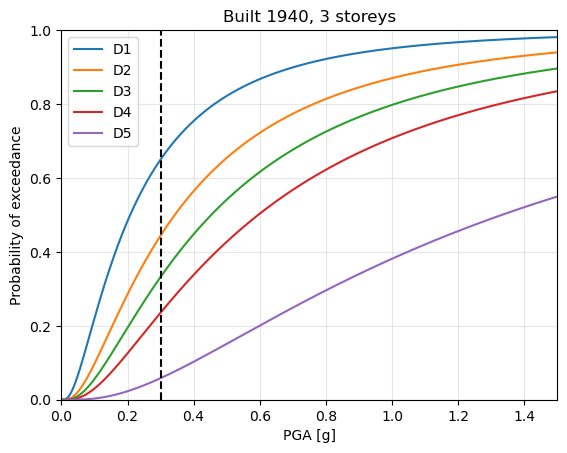

In [11]:
uf.plot_fragility(year, Ns, "PGA", mark=im_value)
plt.show()

### Plotting all intensity measures side by side:

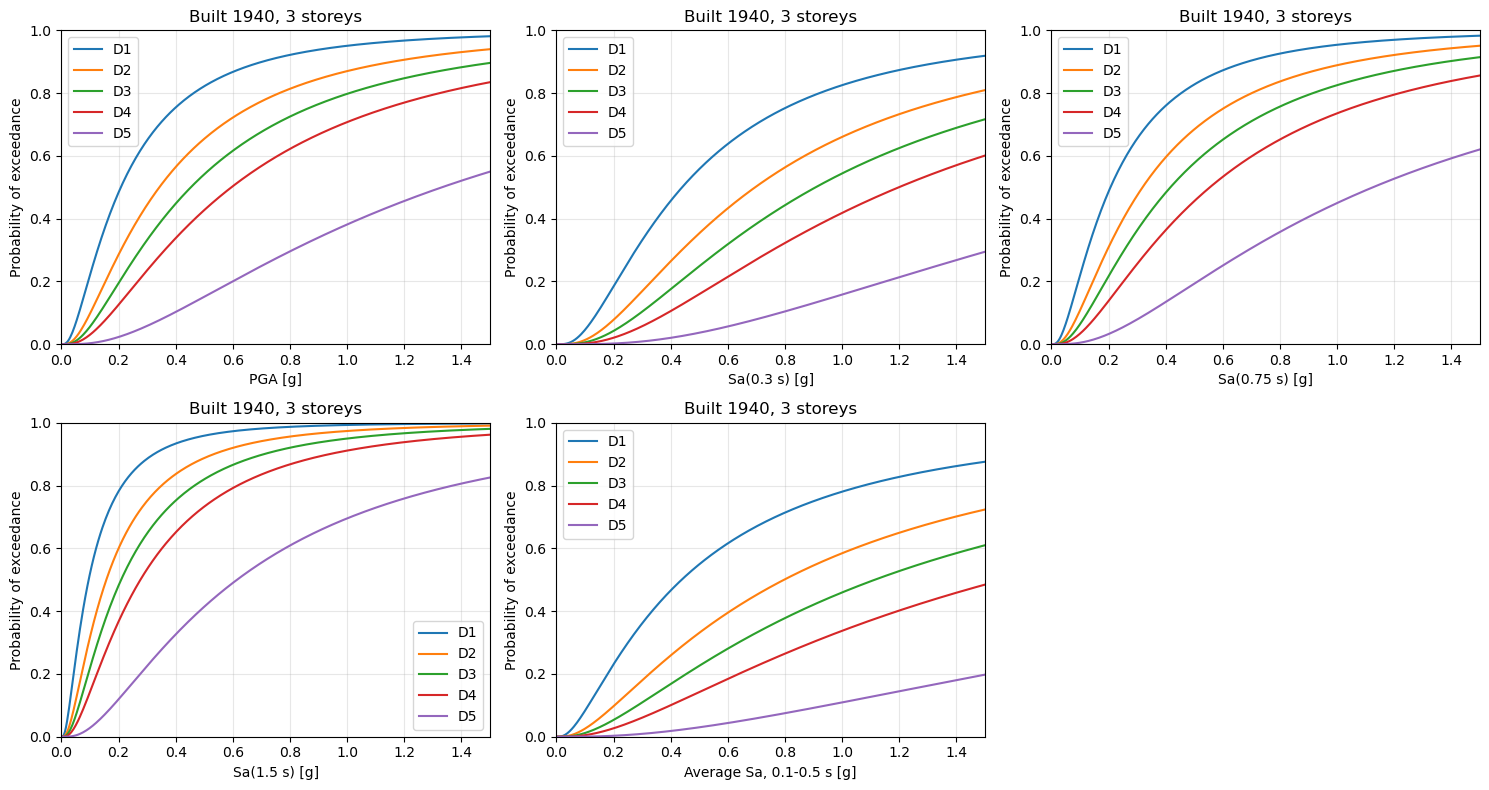

In [6]:
plt.figure(figsize=(15, 8))
for i, im in enumerate(ims, start=1):
    plt.subplot(2, 3, i)
    uf.plot_fragility(year, Ns, im)
plt.tight_layout()
plt.show()



## Notes

* `Sa_0.3`, `Sa_0.75` and `Sa_1.5` use Sa at a single period. `Sa_avg` is an average over 0.1-0.5 s. Use each with its own `im` name.
* The curves come from the Emilia 2012 earthquakes and URM buildings only. The authors recommend using them for earthquakes with similar seismological features.
* The results are the probability of damage **given** an IM value. They are not annual probabilities.